# Downscaling lab: evaluation

Compares every evaluated run of one experiment with the regional climate model (RCM) "truth" and with the published
CORDEX-ML-Bench entries. Heavy computation happens beforehand in `dslab evaluate` (batch job), which writes small
`scores.json` / `diagnostics.nc` files per run and split; this notebook only loads and plots them (≈ 30 s).

**How to read it.** Every figure cell starts with a caption generated from the experiment configuration: what is
shown, what the models were *trained* on, and what they are *evaluated* on. Below each figure, a short findings note
summarises what it shows; these notes are dated snapshots and must be updated when runs are added or changed.

**Run it:** JupyterHub, preset *interactive* (10 GB), kernel **dslab**; or headless with `sbatch jobs/notebook.sbatch`.
Colours are fixed per run; the RCM truth is always black, the climatology floor and published entries grey.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from dslab import plotting as P
from dslab import results
from dslab.experiment import Experiment

EXPERIMENT = "alps_esd"                 # e.g. "alps_emulator" for the Emulator experiment
EXP = Experiment.load(EXPERIMENT)
RUNS = results.list_runs(EXP)           # or an explicit list, e.g. ["climatology", "linear"]
SPLIT = "historical_perfect"            # main test split
FUTURE = next(s for s, t in EXP.reference["splits"].items() if t == "lower_right")
# Published entries listed in the tables (the strip plots and rank tables use all of them)
REF_MODELS = ["Prithvi-UNet-orog", "RCMGEM-mv-orog", "CorrDiff-TW1_NTNU-CWA-orog", "FlowMatching-v1-orog",
              "DetUNet-orog", "DeepESD-IFCAv1-orog"]
FIG_DIR = EXP.eval_dir / "figures"      # None: do not save figures

P.setup_style()
COLORS = P.run_colors(RUNS)
save = (lambda name: FIG_DIR / f"{name}.png") if FIG_DIR else (lambda name: None)
scores = results.load_scores(EXP)
cap = lambda shown, splits=SPLIT: display(results.caption(EXP, shown, splits, RUNS, scores))  # noqa: E731


def fmt(v):
    if isinstance(v, str) or pd.isna(v):
        return "" if not isinstance(v, str) else v
    a = abs(v)
    return f"{v:.3f}" if a < 0.1 else f"{v:.2f}" if a < 10 else f"{v:.1f}" if a < 100 else f"{v:.0f}"


print(EXP.description, "| runs:", RUNS)

ESD pseudo-reality, ALPS, CNRM-CM5-driven ALADIN63, train 1961-1980 | runs: ['climatology', 'deepesd', 'linear', 'unet']


## Experiments

Two kinds of "experiment" appear in this notebook: the **benchmark experiments** (which data a model is trained and
tested on, defined by CORDEX-ML-Bench) and the **model runs** (which method is trained, defined by us). Every model
run is trained within one benchmark experiment and then evaluated on that experiment's test sets.

### Benchmark experiments (CORDEX-ML-Bench)

The task is the same in both experiments: learn the mapping from large-scale atmospheric predictors (u, v, t, z, q
at 850/700/500 hPa on a 16 × 16 grid at 2°) to daily precipitation (`pr`) and maximum temperature (`tasmax`) on the
128 × 128 grid (12.5 km) of a regional climate model (RCM; here ALADIN63 driven by the global model CNRM-CM5). Both
experiments train on *perfect* predictors; they differ in the training period and therefore in what the tests probe.

| | **Experiment 1: ESD pseudo-reality** (`alps_esd`) | **Experiment 2: Emulator hist+future** (`alps_emulator`) |
|---|---|---|
| idea | classic statistical downscaling: learn from a present-day period, apply it to other periods | RCM emulator: learn from present-day and end-of-century climate, fill in between |
| training period | 1961–1980 (20 years) | 1961–1980 + 2080–2099 (40 years) |
| main question | does the model **extrapolate** to a warmer climate it has never seen? | does it **interpolate** to an intermediate climate and transfer to other GCMs? |
| tests | 1 perfect cross-validation 1981–2000 · 2 imperfect cross-validation · 3 perfect extrapolation 2041–2060 + 2080–2099 · 4 imperfect extrapolation · 5 perfect extrapolation with another GCM | 1 perfect cross-validation · 2 imperfect cross-validation · 3 perfect interpolation 2041–2060 · 4 imperfect interpolation · 5/6 perfect/imperfect interpolation with another GCM |
| published scorecard (paper Figs. S12/S13) | Test 1 (upper-left triangle), Test 3 (lower-right) | Test 1, Test 3 |

The test names combine three ideas:

* **Perfect vs. imperfect predictors.** *Perfect* predictors are the RCM's own fields upscaled to the 2° grid: they
  are consistent with the targets, so all remaining error is downscaling error. *Imperfect* predictors are the fields
  of the driving GCM, which is what a model receives in a real application; they add GCM biases and mismatches between
  predictors and targets.
* **Cross-validation / extrapolation / interpolation** say where the test period lies relative to the training period:
  same climate, outside it, or between two training periods.
* **GCM transferability.** The same RCM driven by a different GCM (MPI-ESM-LR instead of CNRM-CM5): does the model
  generalise beyond the one simulation it was trained on?

The table below is generated from the experiment configuration: it lists this experiment's tests, the split that
implements each, and which runs have been evaluated on it so far.

In [2]:
display(Markdown(f"**{EXP.name}**: {EXP.description}. Truth: {EXP.truth}."))
results.benchmark_tests(EXP, RUNS)

**alps_esd**: ESD pseudo-reality, ALPS, CNRM-CM5-driven ALADIN63, train 1961-1980. Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.

,name,split,period,predictors,driving GCM,in published scorecard,evaluated runs
test,,,,,,,
Test 1,perfect cross-validation,historical_perfect,1981–2000,perfect (upscaled RCM),CNRM-CM5,yes,"climatology, deepesd, linear, unet"
Test 2,imperfect cross-validation,historical_imperfect,1981–2000,imperfect (GCM),CNRM-CM5,,—
Test 3,perfect extrapolation,mid_end_century_perfect,2041–2060 + 2080–2099,perfect (upscaled RCM),CNRM-CM5,yes,"climatology, deepesd, linear, unet"
Test 4,imperfect extrapolation,mid_end_century_imperfect,2041–2060 + 2080–2099,imperfect (GCM),CNRM-CM5,,—
Test 5,perfect extrapolation (GCM transferability),mid_end_century_perfect_MPI-ESM-LR,2041–2060 + 2080–2099,perfect (upscaled RCM),MPI-ESM-LR,,—


Training and model selection use only the training file, never a test set:

In [3]:
display(Markdown("\n".join(f"- {results.describe_split(EXP, s)}" for s in ["train", "val"])))

- `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields)
- `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields)

### Model runs: the method ladder

Each run is one model fitted on `train` (hyperparameters / early stopping on `val`) and evaluated on the test splits.
The ladder adds one ingredient per step, so the gain of each can be seen. The generative models and your own model
will use the same data, splits and evaluation.

| run | what it is | input → output | training (here) | why it is on the ladder |
|---|---|---|---|---|
| `climatology` | mean of each calendar day over the training years, 31-day smoothing | date only → pr, tasmax | averaging; CPU, < 1 s | floor: no weather information at all |
| `linear` | ridge regression of every grid point on the principal components of the predictors | 15 × 16 × 16 predictors → 2 × 128 × 128 | closed form, k and α chosen on `val`; CPU, 1 min | classic statistical downscaling: how far does a linear model get? |
| `deepesd` | 3 conv layers on the coarse grid + one dense layer to every grid point (the benchmark's reference CNN) | 15 × 16 × 16 → 2 × 128 × 128 | MSE on standardised sqrt(pr), tasmax; 1 A100, 2 min | non-linearity; reproduces a published entry (pipeline check) |
| `unet` | residual U-Net on the target grid; predictors interpolated to every grid point, orography added | 16 × 128 × 128 → 2 × 128 × 128 | as `deepesd`; 1 A100, 7 min | spatial structure on the fine grid; strongest deterministic model; backbone for the generative models |
| *flow matching (planned)* | conditional generative model on the same U-Net backbone; plain, and residual on top of `unet` | as `unet` + noise → ensembles | flow-matching loss | realistic texture, extremes and ensembles |
| *your model (planned)* | adaptive flow matching | | | |

All current runs are deterministic: they predict one field per day, the conditional mean. For scale: training all
four took about 10 minutes of one GPU; CorrDiff-TW1, the most expensive published entry, reports 8 × H200 × 17.5 h
(about 140 GPU-hours). The table below is generated from the run directories.

In [4]:
results.run_info(EXP, RUNS)[["model", "summary", "n_params", "hardware", "fit_seconds", "epochs", "selected"]]

,model,summary,n_params,hardware,fit_seconds,epochs,selected
run,,,,,,,
climatology,climatology,mean of each calendar day over the training ye...,NaN,CPU,0.4,NaN,None
deepesd,deepesd,benchmark reference CNN: 3 conv layers on the ...,8439677.0,NVIDIA A100-SXM4-80GB,111.7,900.0,"{'pr': {'best_epoch': 869, 'val_rmse': 4.32708..."
linear,linear,ridge regression of every target grid point on...,NaN,CPU,54.1,NaN,"{'pr': {'n_pcs': 3840, 'alpha': 10.0, 'val_rms..."
unet,unet,residual U-Net on the target grid; predictors ...,9841922.0,NVIDIA A100-SXM4-80GB,419.2,35.0,"{'pr': {'best_epoch': 26, 'val_rmse': 3.737090..."


## Metrics in brief

Two families of metrics answer different questions:

* **Accuracy** — does the model get each *day* right? (RMSE, MAE, correlation, CRPS). A deterministic regression
  trained with MSE predicts the conditional mean, which minimises these by construction but is too smooth.
* **Realism / climate statistics** — does the model produce the right *climate*: mean, extremes, variability,
  spatial texture, distribution? (Mean bias, SDII, Rx1day, TXx, IAV, RALSD, LHD, PSS). These ignore the timing of
  individual days, so a realistic generative model can do well here while having a larger day-by-day error.

Generative models are scored with the ensemble mean for RMSE / mean bias and with individual members for the
realism metrics, as in the benchmark. A good downscaling model needs both families.

| metric | what it measures | units | ideal | published ALPS ESD range (min · median · max, 40 entries) | how to read it |
|---|---|---|---|---|---|
| **RMSE** | daily error over all days and grid points (ensemble mean) | mm/day, K | 0 | pr 3.63 · 4.63 · 6.46; tasmax 1.26 · 1.56 · 9.94 | day-by-day accuracy; favours smooth predictions |
| **Mean Bias** | bias map of the time mean, reduced as RMS over grid points | mm/day, K | 0 | pr 0.16 · 0.38 · 1.39; tasmax 0.09 · 0.29 · 6.35 | systematic climate error; positive and negative regions do **not** cancel, the sign is lost (see "Bias (domain mean)") |
| **SDII** (pr) | bias of mean precipitation on wet days (≥ 1 mm/day) | mm/day | 0 | 0.41 · 1.42 · 3.73 | rain intensity; drizzle (many light-rain days) lowers it |
| **Rx1day** (pr) | bias of the mean annual maximum daily precipitation | mm/day | 0 | 5.8 · 12.3 · 28.9 | heavy-rain extremes |
| **TXx** (tasmax) | bias of the mean annual maximum of tasmax | K | 0 | 0.41 · 1.06 · 8.23 | hot extremes |
| **IAV** (tasmax) | bias of the standard deviation of annual means | K | 0 | 0.075 · 0.14 · 0.37 | year-to-year variability |
| **RALSD** | mean squared dB difference between time-mean radial power spectra, over 90 bins incl. 25 beyond Nyquist (one member) | dB² | 0 | pr 0.09 · 7.4 · 377; tasmax 0.025 · 4.7 · 205 | spatial texture: < 1 very realistic, > 10 clearly too smooth or too noisy; dominated by pixel-scale detail (section 6) |
| **LHD** (pr) | RMS dB difference between histograms of all daily values (10 mm/day bins, bins with > 10 counts) | dB | 0 | 0.31 · 1.41 · 4.27 | shape of the distribution incl. heavy tail; > 3 = clearly wrong frequencies |
| **PSS** (tasmax) | overlap of the normalised histograms (1 °C bins) | – | 1 | 0.81 · 0.97 · 0.99 | distribution similarity; saturates near 0.97–0.99 |
| MAE | mean absolute daily error | mm/day, K | 0 | – | like RMSE, less sensitive to large errors |
| Bias (domain mean) | signed mean error over all days and points | mm/day, K | 0 | – | the sign that "Mean Bias" hides |
| Corr (temporal) | Pearson correlation over time at each grid point, averaged | – | 1 | – | timing of day-to-day variations |
| P99 bias | RMS over grid points of the 99th-percentile bias map | mm/day, K | 0 | – | local extremes (daily, not annual) |
| Wet-day freq bias (pr) | RMS of the bias map of the fraction of days ≥ 1 mm/day | – | 0 | – | drizzle / missing rain days |
| CRPS | continuous ranked probability score (fair, per ensemble) | mm/day, K | 0 | – | probabilistic accuracy; equals MAE for deterministic runs |
| Spread/skill | ensemble spread / RMSE of the ensemble mean | – | 1 | – | < 1 over-confident, > 1 under-confident (ensembles only) |

Exact definitions, as implemented by the benchmark organisers, are in `docs/metric_definitions.md`.

## 1. Training of the neural runs

**Shown:** training curves of the neural runs: loss (MSE of per-grid-point standardised sqrt(pr) and tasmax) per epoch on the training data (left) and on the validation years (right); the dot marks the epoch whose weights are kept (early stopping).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

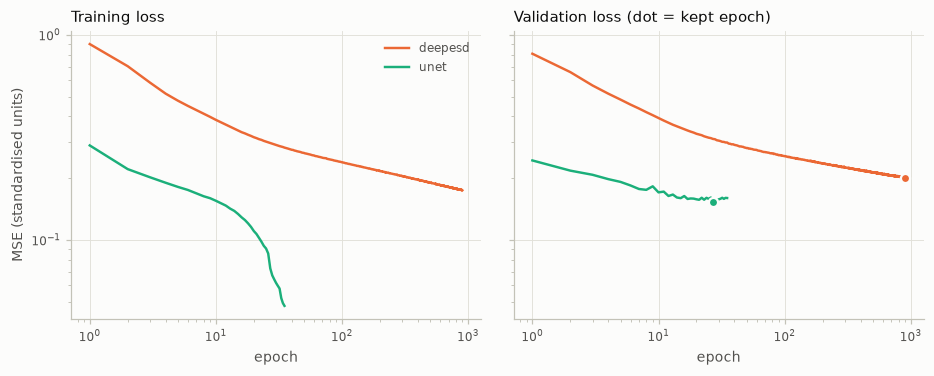

In [5]:
hist = {r: h for r in RUNS if (h := results.load_history(EXP, r)) is not None}
cap("training curves of the neural runs: loss (MSE of per-grid-point standardised sqrt(pr) and tasmax) per epoch "
    "on the training data (left) and on the validation years (right); the dot marks the epoch whose weights are kept "
    "(early stopping).", "val")
P.fig_training_curves(hist, COLORS, save=save("training_curves")) if hist else print("no neural runs yet");

**Findings** *(snapshot 2026-10-30, runs: climatology, deepesd, linear, unet; update when runs change)*
- **DeepESD** (8.4 M parameters) converges slowly but steadily; training and validation loss stay close (0.176 vs.
  0.201 at the kept epoch 869 of 900): no overfitting. Early stopping ended it while it was still improving very
  slightly.
- **U-Net** (9.8 M parameters) reaches a much lower validation loss within a few epochs (0.153 at epoch 26), then
  overfits: training loss keeps falling (0.048) while validation loss rises. Early stopping keeps the epoch-26
  weights; more regularisation (dropout, weight decay, augmentation) or a smaller network may help.
- Both losses are on the same standardised targets, so the U-Net's validation loss is about 25% lower than DeepESD's.

## 2. Scorecard against the published entries

The 12 metrics of the benchmark paper (supplement Figs. S12/S13), computed exactly as in the organisers' code. Each
grey dot is one published ALPS ESD entry (with- and without-orography variants count separately); diamonds are our
runs. The first table lists the scores, the second how many of the published entries score **better** than each of
our runs (e.g. `2 / 40`: only two published entries are better).

**Shown:** the 12 published scorecard metrics: published entries (grey dots) and our runs (diamonds); lower is better except PSS.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

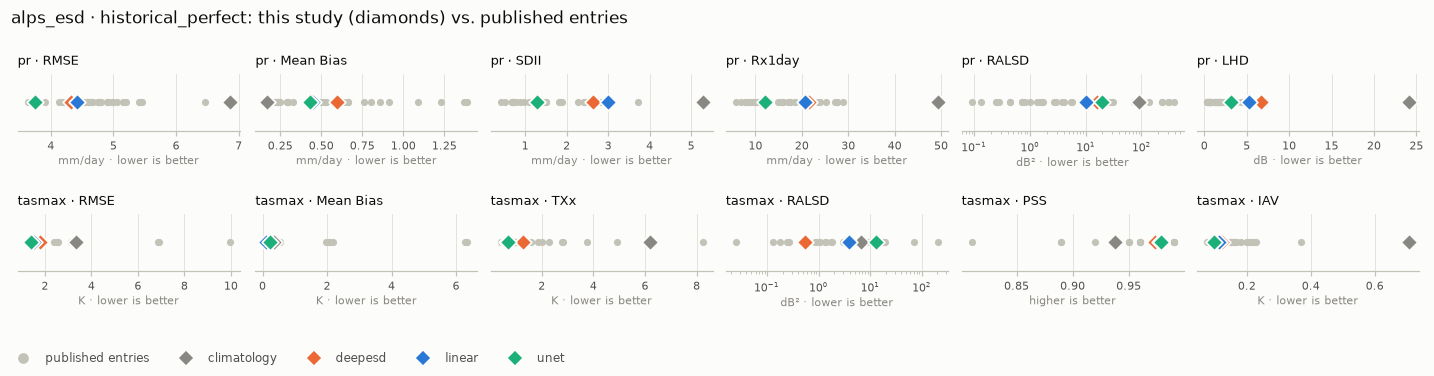

In [6]:
def show_card(card):
    def best(col):
        target = col.max() if col.name[-1] in ("PSS", "Corr (temporal)") else col.abs().min()
        return ["font-weight: 600; background-color: #cde2fb" if pd.notna(v) and abs(v) == abs(target) else ""
                for v in col]
    return card.style.format(fmt).apply(best, axis=0)


cap("the 12 published scorecard metrics: published entries (grey dots) and our runs (diamonds); lower is better "
    "except PSS.")
card = results.scorecard(EXP, SPLIT, RUNS, scores=scores)
P.fig_scorecard_strips(card, COLORS, title=f"{EXP.name} · {SPLIT}: this study (diamonds) vs. published entries",
                       save=save(f"scorecard_{SPLIT}"))
plt.show()
display(show_card(results.scorecard(EXP, SPLIT, RUNS, REF_MODELS, scores=scores)))
display(results.rank_vs_published(card).style.set_caption("number of published entries that score better"))

**Findings** *(snapshot 2026-10-30, runs: climatology, deepesd, linear, unet; update when runs change)* — historical test period
- The **U-Net** is our best model on 8 of 12 metrics. Its pr RMSE (3.75 mm/day) is the third lowest of the 40
  published entries (only Prithvi-UNet-orog 3.63 and RCMGEM-mv-orog 3.74 are lower; CorrDiff-TW1 3.77); for tasmax
  RMSE (1.40 K) six entries are better (best 1.26 K).
- Our **DeepESD** reproduces the published DeepESD's pr RMSE (4.33 vs. 4.32 mm/day), a check that data, training and
  scoring are consistent with the benchmark.
- All our models are deterministic regressions and rank poorly on the realism metrics: for pr LHD 36–40 of 40
  published entries are better, for RALSD 22–26. They predict the conditional mean, which is smooth, has too much
  drizzle and too weak extremes. Generative entries do far better there (e.g. FlowMatching-v1: pr RALSD 0.28, LHD 0.32).
- Climatology has the lowest pr Mean Bias (0.17): all trained models share a dry bias (section 3).

**Future period.** For ESD the benchmark pools 2041–2060 and 2080–2099. The models never saw this climate,
so this measures extrapolation. Which period the published LHD/PSS values refer to cannot be determined from the
organisers' code; read those two with care.

**Shown:** the 12 published scorecard metrics for the future period; same layout as above.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `mid_end_century_perfect` (2041–2060 + 2080–2099 pooled; 14610 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

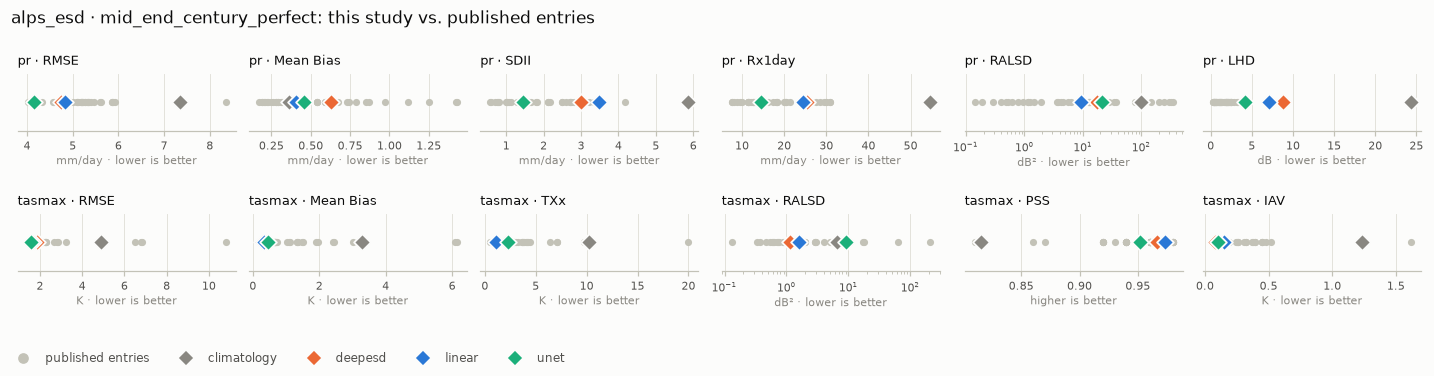

In [7]:
cap("the 12 published scorecard metrics for the future period; same layout as above.", FUTURE)
card_f = results.scorecard(EXP, FUTURE, RUNS, scores=scores)
P.fig_scorecard_strips(card_f, COLORS, title=f"{EXP.name} · {FUTURE}: this study vs. published entries",
                       save=save(f"scorecard_{FUTURE}"))
plt.show()
display(show_card(results.scorecard(EXP, FUTURE, RUNS, REF_MODELS, scores=scores)))
display(results.rank_vs_published(card_f).style.set_caption("number of published entries that score better"))

**Findings** *(snapshot 2026-10-30, runs: climatology, deepesd, linear, unet; update when runs change)* — future period (extrapolation)
- Rankings mostly carry over. U-Net pr RMSE 4.15 mm/day; lower are only Prithvi-UNet-orog (4.01), RCMGEM-mv-orog
  (4.13) and CorrDiff-TW1 (4.14, both orography variants).
- For temperature extrapolation the **linear** model is best of ours (tasmax Mean Bias 0.34 K, TXx 1.11 K). The U-Net
  underestimates future hot extremes (TXx 2.24 K, PSS 0.951): the non-linear models extrapolate less reliably beyond
  the training climate.
- Climatology's tasmax Mean Bias jumps from 0.36 to 3.3 K because it has no warming by construction.

## 3. All metrics, all splits

Scorecard plus development metrics (see "Metrics in brief"). `val` is what model selection sees; the test splits
should only be looked at for finished models.

In [8]:
def all_metrics(split):
    s = scores[(scores.split == split) & scores.run.isin(RUNS)]
    return s.pivot_table(index="run", columns=["variable", "metric"], values="value", sort=False).reindex(RUNS)

for split in ["val", SPLIT, FUTURE]:
    cap("all metrics (rows: runs; columns: variable and metric).", split)
    display(all_metrics(split).style.format(fmt))

**Shown:** all metrics (rows: runs; columns: variable and metric).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

**Shown:** all metrics (rows: runs; columns: variable and metric).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

**Shown:** all metrics (rows: runs; columns: variable and metric).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `mid_end_century_perfect` (2041–2060 + 2080–2099 pooled; 14610 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

**Findings** *(snapshot 2026-10-30, runs: climatology, deepesd, linear, unet; update when runs change)*
- **Systematic dry bias** of all trained models: the domain-mean pr bias is −0.39 (U-Net) to −0.55 mm/day (DeepESD),
  i.e. −13 to −18% of the 3.0 mm/day mean, on validation and test alike. Likely cause: training with MSE on sqrt(pr)
  predicts the conditional mean of sqrt(pr), and squaring it underestimates the mean of pr (Jensen's inequality).
  Climatology, which averages raw pr, has no such bias. Fixable (e.g. train on raw pr or correct the variance);
  generative models avoid it by sampling.
- Validation and test scores are almost identical (U-Net pr RMSE 3.74 vs. 3.75, tasmax 1.41 vs. 1.40 K), so the two
  validation years are a reliable stand-in for model selection.
- Temporal correlation: pr 0.74 (linear) → 0.77 (DeepESD) → 0.81 (U-Net); tasmax ≥ 0.97 for all trained models
  (climatology 0.90 from the seasonal cycle alone).
- Wet-day frequency: linear and DeepESD produce too many wet days (+0.08, +0.05); the U-Net is nearly unbiased (+0.01).

## 4. Maps on the test period

Maps are drawn in the RCM's own Lambert projection (exact grid). Bias = prediction − truth, with a shared colour
scale per column. Precipitation: blue = too wet, red = too dry. Temperature: red = too warm, blue = too cold.

**Shown:** precipitation. Top row: RCM truth of the time mean, Rx1day (mean annual maximum), SDII (mean intensity on days ≥ 1 mm) and wet-day fraction (days ≥ 1 mm). Other rows: bias of each run.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

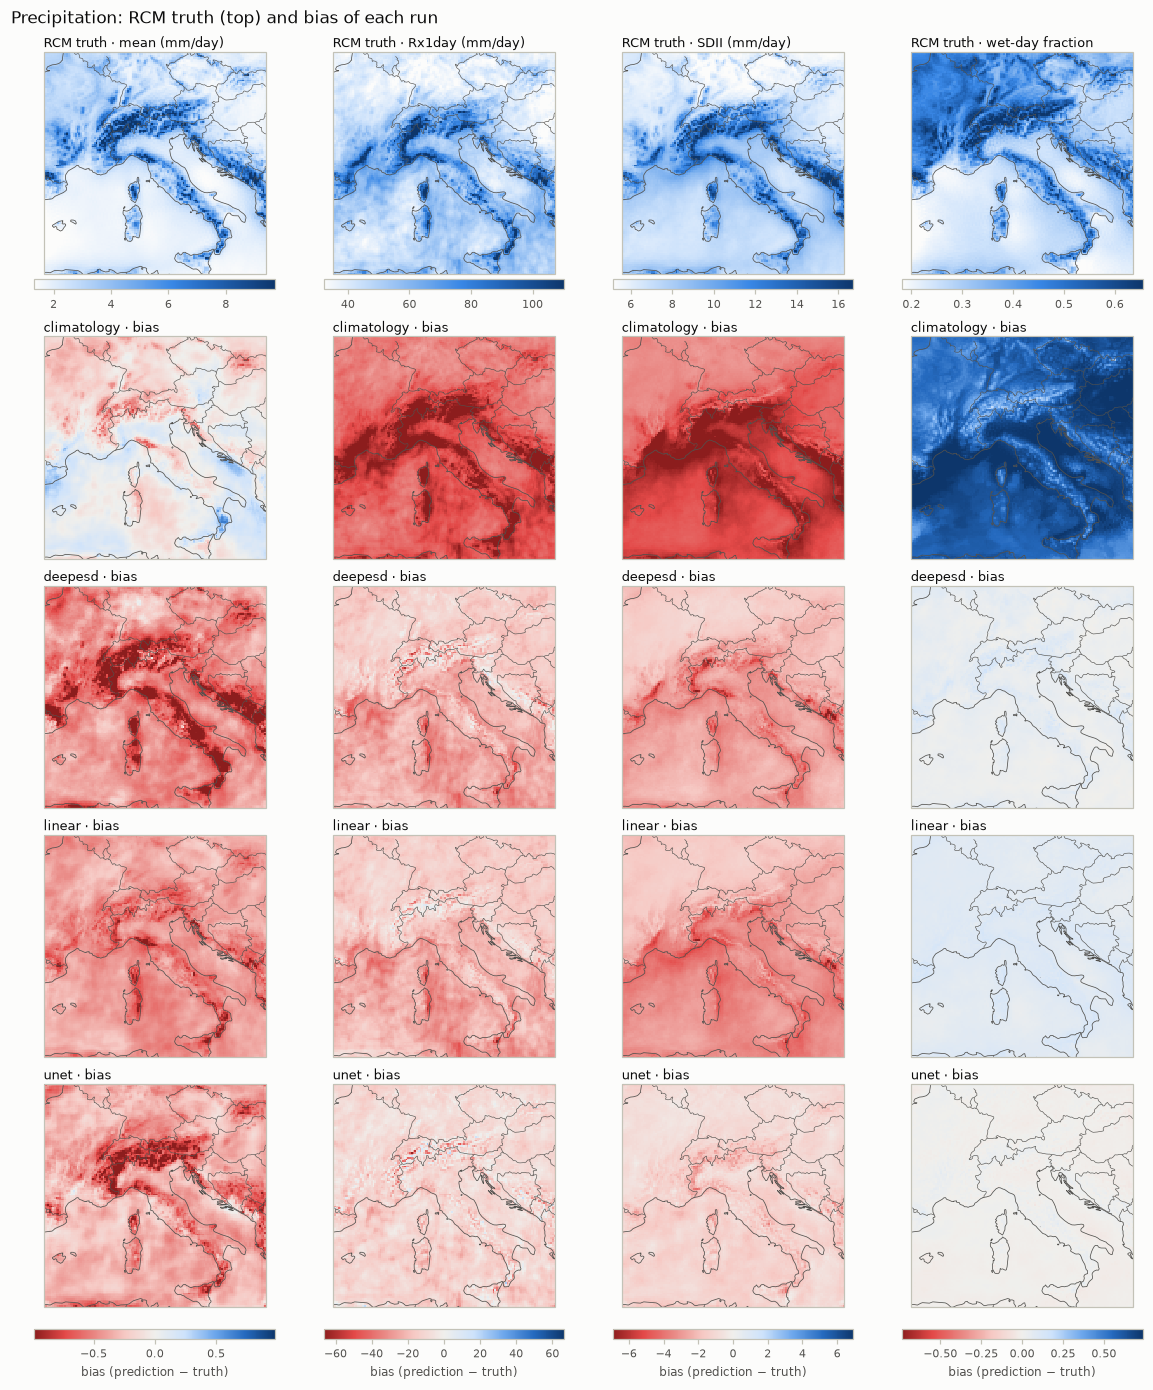

In [9]:
D = {r: results.load_diagnostics(EXP, r, SPLIT) for r in RUNS}
MG = P.MapGrid.from_experiment(EXP, D[RUNS[0]])
cap("precipitation. Top row: RCM truth of the time mean, Rx1day (mean annual maximum), SDII (mean intensity on "
    "days ≥ 1 mm) and wet-day fraction (days ≥ 1 mm). Other rows: bias of each run.")
P.fig_bias_maps(D, "pr", [("mean", "mean (mm/day)"), ("Rx1day", "Rx1day (mm/day)"),
                          ("SDII", "SDII (mm/day)"), ("wetfrac", "wet-day fraction")], MG,
                save=save(f"maps_pr_{SPLIT}"));

**Findings** *(snapshot 2026-10-30, runs: climatology, deepesd, linear, unet; update when runs change)*
- Truth: mean precipitation, extremes and wet-day frequency are highest over the Alps, the Apennines and the Dinaric Alps.
- All trained models are too dry almost everywhere, most over high terrain (mean bias above 1000 m: linear −0.57,
  DeepESD −0.91, U-Net −0.78 mm/day; below 300 m: −0.41, −0.47, −0.33).
- Extremes are underestimated everywhere: Rx1day by 19 (linear), 20 (DeepESD) and 11 mm/day (U-Net) on average,
  against a truth of 52 mm/day; SDII by 2.9, 2.5 and 1.2 mm/day. The U-Net roughly halves the deficit.
- Climatology rains nearly every day (wet-day fraction +0.6) because its smoothed mean is rarely below 1 mm/day.

**Shown:** daily maximum temperature. Top row: RCM truth of the time mean, TXx (mean annual maximum), 99th percentile and IAV (standard deviation of annual means). Other rows: bias of each run.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

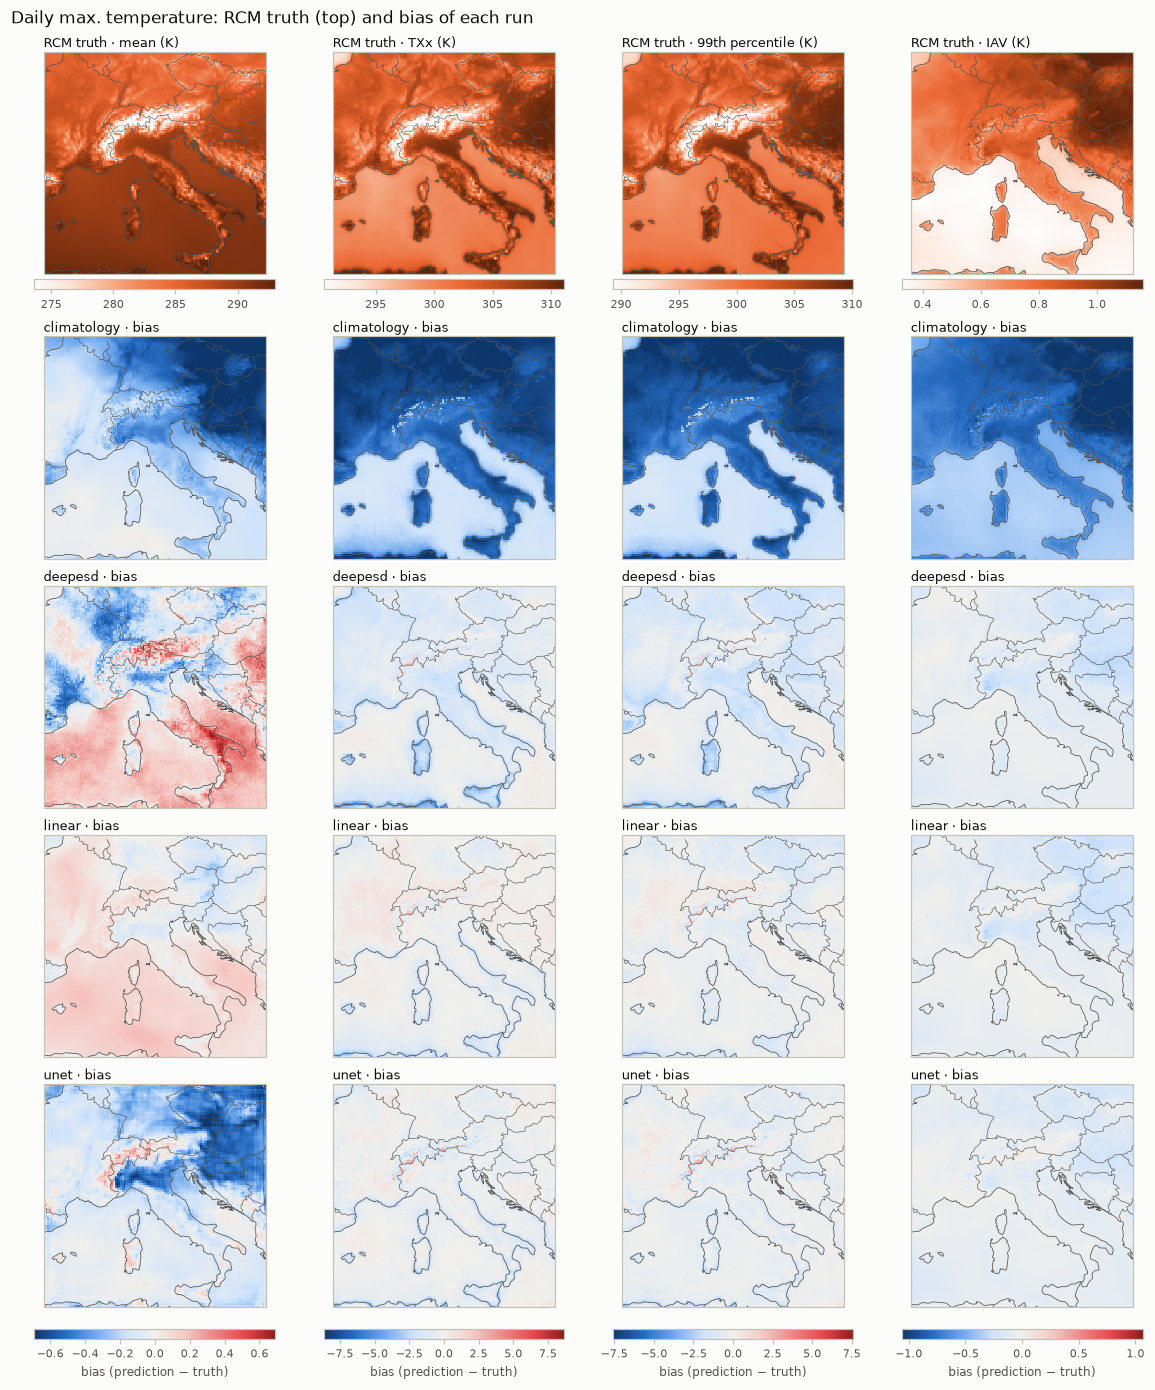

In [10]:
cap("daily maximum temperature. Top row: RCM truth of the time mean, TXx (mean annual maximum), 99th percentile "
    "and IAV (standard deviation of annual means). Other rows: bias of each run.")
P.fig_bias_maps(D, "tasmax", [("mean", "mean (K)"), ("TXx", "TXx (K)"),
                              ("p99", "99th percentile (K)"), ("IAV", "IAV (K)")], MG,
                save=save(f"maps_tasmax_{SPLIT}"));

**Findings** *(snapshot 2026-10-30, runs: climatology, deepesd, linear, unet; update when runs change)*
- Truth: orography dominates the mean and the extremes; interannual variability is largest in the continental northeast.
- Mean biases are small for all trained models (domain mean −0.17 to +0.05 K, 90% of grid points within about
  ±0.5 K); the U-Net is slightly too cold, mostly in the lowlands.
- Hot extremes are underestimated: TXx by 0.24 (linear), 0.40 (U-Net) and 0.98 K (DeepESD, up to −2.4 K locally).
- All trained models slightly underestimate interannual variability (IAV −0.08 to −0.10 K). Climatology has no
  day-to-day or interannual variability, so its TXx and 99th percentile are several kelvin too low.

**Shown:** day-to-day skill at every grid point: RMSE (first and third figure; ensemble mean for stochastic runs) and temporal correlation with the truth (second and fourth). Correlation colour scales start at 0.5 (pr) and 0.9 (tasmax); lower values share the lightest colour.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

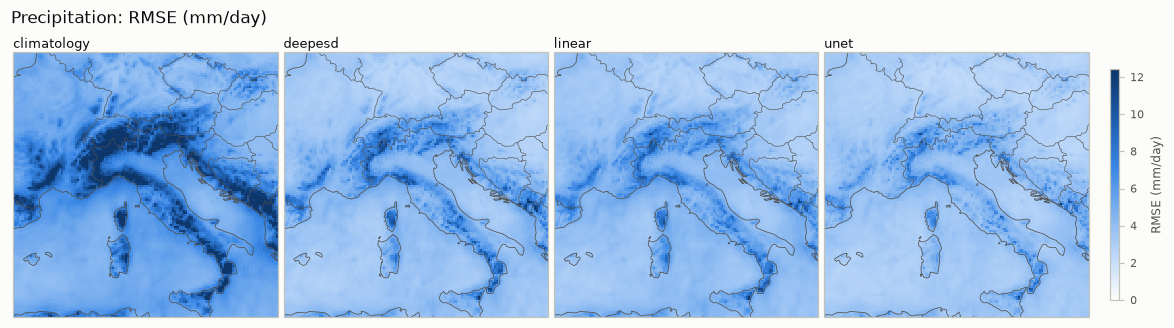

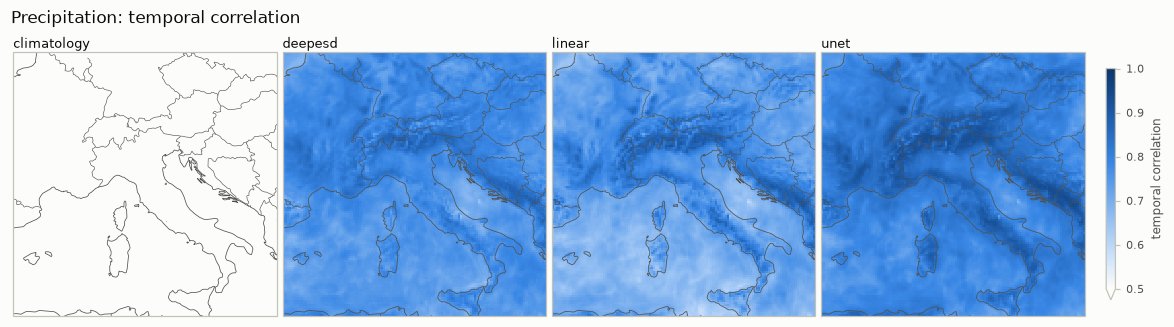

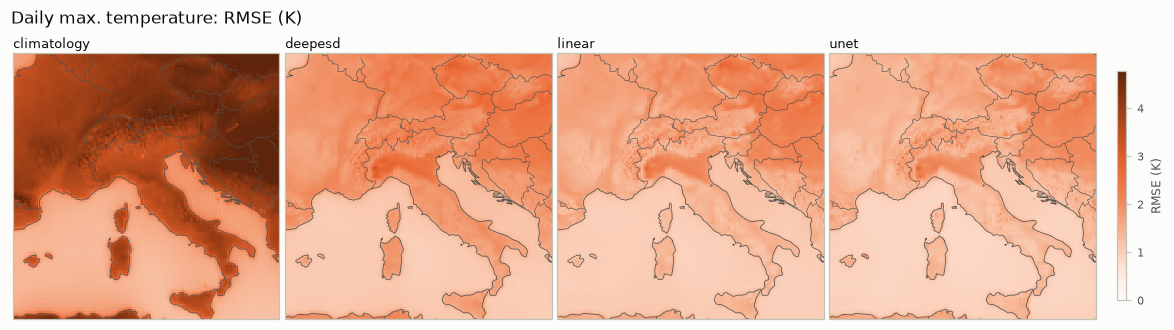

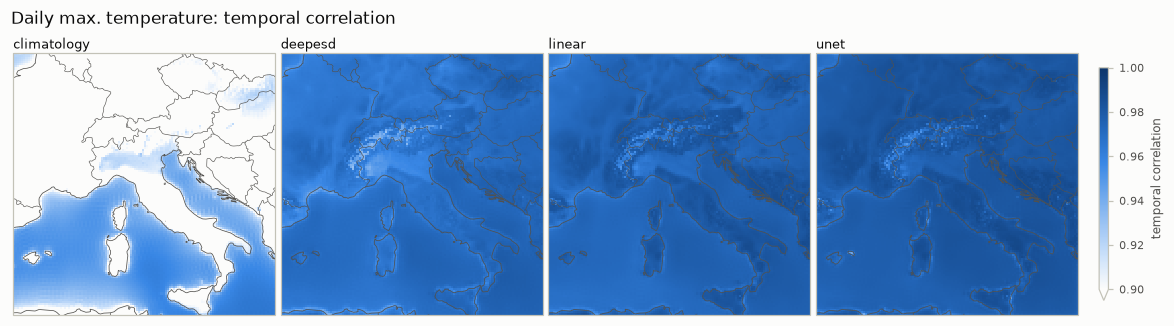

In [11]:
cap("day-to-day skill at every grid point: RMSE (first and third figure; ensemble mean for stochastic runs) and "
    "temporal correlation with the truth (second and fourth). Correlation colour scales start at 0.5 (pr) and 0.9 "
    "(tasmax); lower values share the lightest colour.")
for var in EXP.variables:
    P.fig_field_maps(D, var, "rmse_map", f"RMSE ({P.UNITS[var]})", MG, cmap=P.SEQ[var], vmin=0,
                     save=save(f"rmse_{var}_{SPLIT}"))
    plt.show()
    P.fig_field_maps(D, var, "corr_map", "temporal correlation", MG, cmap=P.SEQ["pr"],
                     vmin={"pr": 0.5, "tasmax": 0.9}.get(var, 0), vmax=1, save=save(f"corr_{var}_{SPLIT}"))
    plt.show()

**Findings** *(snapshot 2026-10-30, runs: climatology, deepesd, linear, unet; update when runs change)*
- Errors follow the precipitation amount: pr RMSE is largest over the mountains (up to ~14 mm/day) and smallest over
  the sea and plains. The U-Net has the lowest error almost everywhere (domain mean 3.62 vs. 4.11 DeepESD, 4.26
  linear, 6.40 mm/day climatology).
- pr correlation: U-Net 0.81 on average (lowest grid point 0.68), DeepESD 0.77, linear 0.74 (lowest 0.58);
  climatology ≈ 0.1, i.e. no daily skill. For all models correlation is highest over the mountains, where
  orographic rain follows the large-scale flow, and lowest over the Tyrrhenian Sea and the Adriatic.
- tasmax correlation is above 0.92 at every grid point for all trained models, highest for the U-Net (0.98).

## 5. Example days

The wettest winter (DJF) day, the wettest summer (JJA) day and the hottest day of the test period (by domain mean of
the truth). Deterministic models show the conditional mean, so they are expected to look smoother than the truth;
a generative model should look like a plausible weather map, not necessarily like this particular one.

**Shown:** single days: pr on 1997-12-06 and 1992-08-28 (log colour scale, < 0.5 mm/day white), tasmax on 2000-08-26; truth (left) and each run (first ensemble member).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

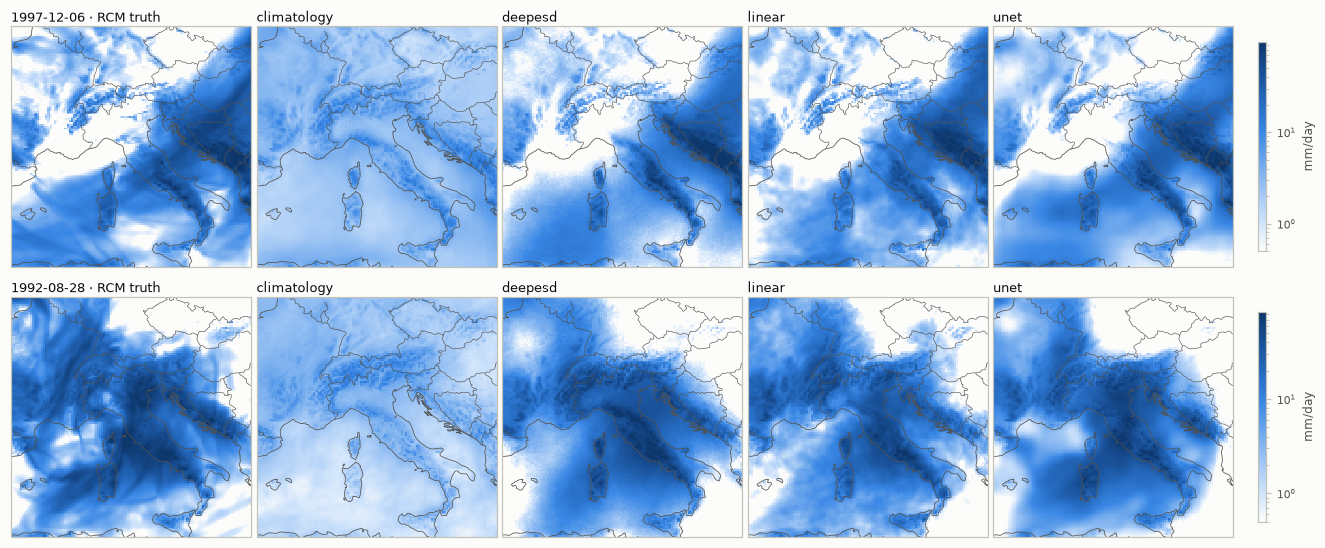

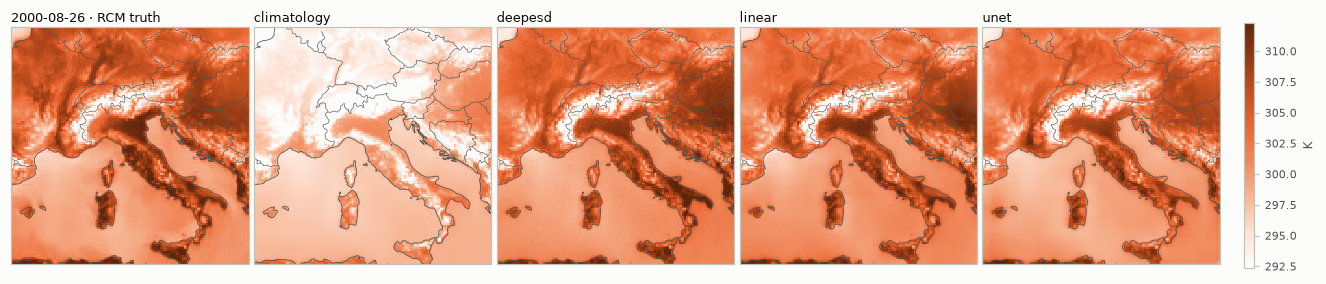

In [12]:
d0 = D[RUNS[0]]
time = pd.DatetimeIndex(d0["time"].values)
pr_dm, tx_dm = d0["pr_series_true"].values, d0["tasmax_series_true"].values
djf, jja = time.month.isin([12, 1, 2]), time.month.isin([6, 7, 8])
dates = [time[djf][np.argmax(pr_dm[djf])], time[jja][np.argmax(pr_dm[jja])], time[np.argmax(tx_dm)]]
cap(f"single days: pr on {dates[0]:%Y-%m-%d} and {dates[1]:%Y-%m-%d} (log colour scale, < 0.5 mm/day white), "
    f"tasmax on {dates[2]:%Y-%m-%d}; truth (left) and each run (first ensemble member).")
for var, days in [("pr", dates[:2]), ("tasmax", dates[2:])]:
    truth = results.load_fields(EXP, SPLIT, days, var)
    preds = {r: results.load_fields(EXP, SPLIT, days, var, run=r) for r in RUNS}
    P.fig_example_days(truth, preds, days, var, MG, save=save(f"days_{var}_{SPLIT}"))
    plt.show()

**Findings** *(snapshot 2026-10-30, runs: climatology, deepesd, linear, unet; update when runs change)*
- All trained models place the weather correctly: the frontal band over the Adriatic and the Balkans in December, the
  widespread rain over the Alps, Italy and the Mediterranean in August, and the pattern of the hottest day.
- The fields are much smoother than the RCM: no streaks or convective cells, and light rain where the truth is dry.
- Amounts on these extreme days are too low: domain means 8.7–9.3 vs. 10.9 mm/day (December) and 10.3–12.1 vs.
  15.3 mm/day (August); on the hottest day 28.6–29.6 vs. 29.9 °C (U-Net lowest).

## 6. Spatial structure: power spectra

Mean radially averaged power spectrum of the daily fields (one member). The right panel is the ratio to the truth in
dB; below 0 dB means too little variance at that scale (too smooth). The published RALSD is the mean square of this
curve over **all 90 bins**, including the 25 bins beyond the Nyquist wavenumber (shaded): the grid's diagonal
"corners", i.e. pixel-scale texture. The table splits RALSD into the two parts.

**Shown:** mean radial power spectra (left) and spectral ratio prediction/truth in dB (right) for pr (first figure) and tasmax (second); table: RALSD over all bins (= published value), over resolved scales and over the corner bins.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

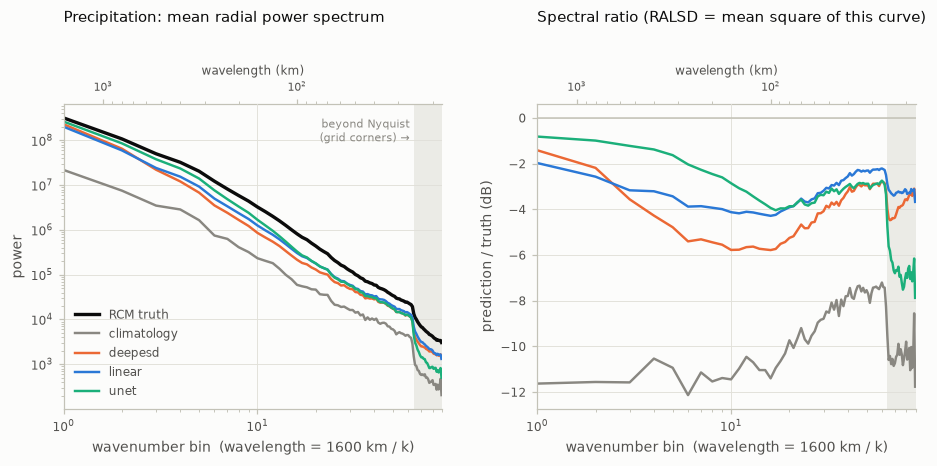

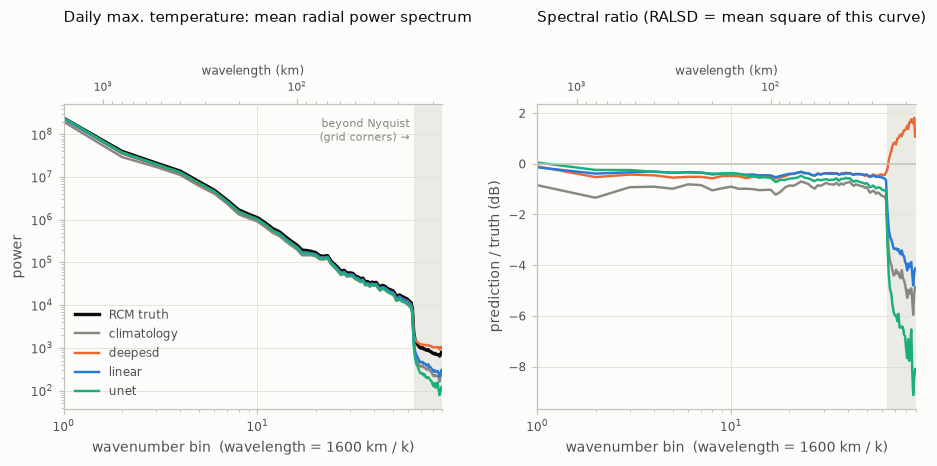

In [13]:
cap("mean radial power spectra (left) and spectral ratio prediction/truth in dB (right) for pr (first figure) and "
    "tasmax (second); table: RALSD over all bins (= published value), over resolved scales and over the corner bins.")
for var in EXP.variables:
    P.fig_spectra(D, var, COLORS, save=save(f"spectra_{var}_{SPLIT}"))
    plt.show()
split_tab = pd.concat({var: pd.DataFrame(P.ralsd_split(D, var)).T for var in EXP.variables}, axis=1)
display(split_tab.style.format(fmt).set_caption("RALSD (dB²)"))

**Findings** *(snapshot 2026-10-30, runs: climatology, deepesd, linear, unet; update when runs change)*
- **tasmax:** up to the Nyquist wavenumber all trained models are within ~0.5 dB of the truth (resolved RALSD
  0.2–0.6 dB²). The published RALSD differs only through the corner bins: DeepESD +1–2 dB there (total 0.56 dB²),
  linear −4 dB (3.97), U-Net −6 to −8 dB (13.1).
- **pr:** all models lack variance at every scale: 0.8–2 dB at the largest scales and 2–6 dB at 30–300 km. The U-Net
  is closest at large scales, DeepESD furthest at 100–300 km. In the corner bins the U-Net loses most (−7 dB), which
  doubles its RALSD (19.7 vs. 9.7 dB² over resolved scales).
- For model development: RALSD is largely a pixel-scale texture score. A model needs realistic grid-scale detail to
  score well, which is what generative models provide.

## 7. Distributions and extremes

Left: density over all days and grid points (log scale; pr dry fraction, < 0.1 mm/day, in the legend). Right:
pooled quantiles 0.5 … 0.9999 against the truth; points below the 1:1 line in the upper tail mean extremes are
underestimated.

**Shown:** distribution of all daily values over the whole domain (left) and quantile-quantile plot (right), for pr (first figure) and tasmax (second).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

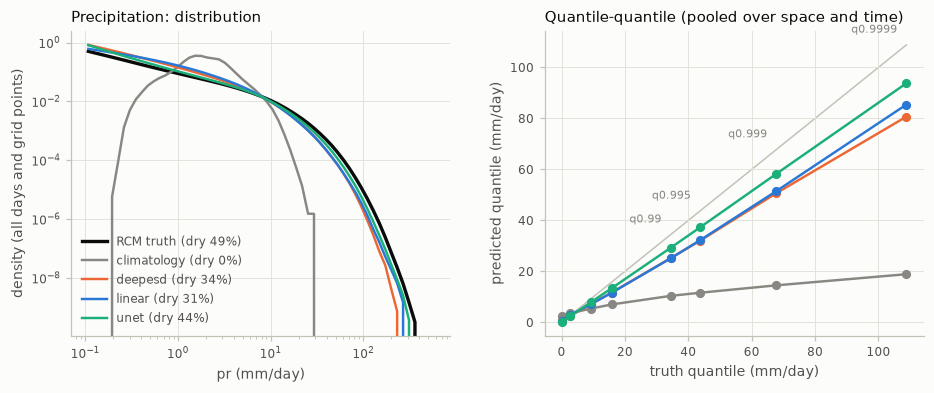

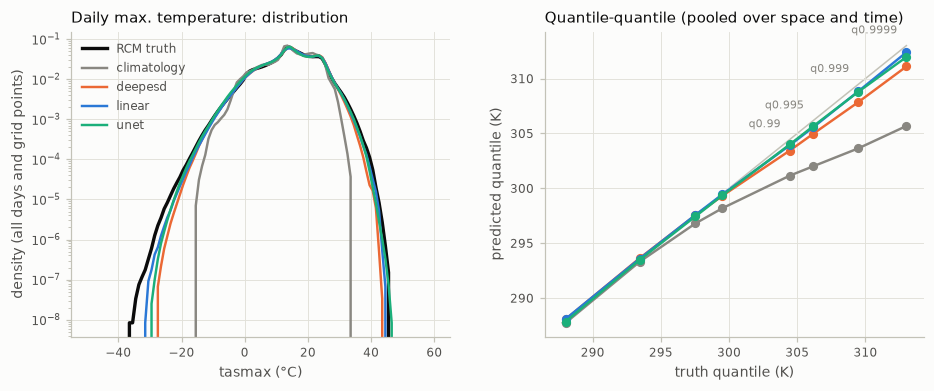

In [14]:
cap("distribution of all daily values over the whole domain (left) and quantile-quantile plot (right), "
    "for pr (first figure) and tasmax (second).")
for var in EXP.variables:
    P.fig_distributions(D, var, COLORS, save=save(f"distributions_{var}_{SPLIT}"))
    plt.show()

**Findings** *(snapshot 2026-10-30, runs: climatology, deepesd, linear, unet; update when runs change)*
- **pr:** the RCM is dry (< 0.1 mm/day) on 49% of grid-point days; the U-Net 44%, DeepESD 34%, linear 31% and
  climatology 0%. The regression models produce drizzle, the U-Net least.
- The heavy tail is too light: the 99.99th percentile is 109 mm/day in the truth vs. 94 (U-Net), 85 (linear), 81
  (DeepESD) and 19 (climatology); the 99th percentile is 34 mm/day in the truth vs. 29 (U-Net) and 25 (linear,
  DeepESD).
- **tasmax:** the distribution is reproduced well (PSS ≥ 0.97); only the upper tail is slightly too cool (99.99th
  percentile 39.9 °C in the truth vs. 37.9–39.2 °C).

## 8. Seasonal cycle of the bias

**Shown:** domain-mean bias (prediction − truth) per calendar month, pr (left) and tasmax (right).  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

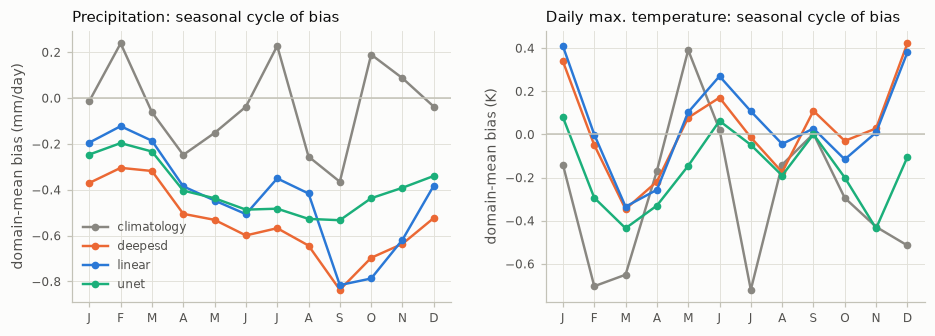

In [15]:
cap("domain-mean bias (prediction − truth) per calendar month, pr (left) and tasmax (right).")
P.fig_seasonal_bias(D, COLORS, EXP.variables, save=save(f"seasonal_{SPLIT}"));

**Findings** *(snapshot 2026-10-30, runs: climatology, deepesd, linear, unet; update when runs change)*
- **pr:** all trained models are too dry in every month (−0.1 to −0.8 mm/day), most in autumn (September–November,
  the wettest season with 3.5–3.8 mm/day): linear and DeepESD −0.6 to −0.8, U-Net −0.4 to −0.5 mm/day.
- **tasmax:** biases stay within ±0.45 K in all months. Linear and DeepESD are slightly warm in December–January
  (+0.3 to +0.4 K), the U-Net slightly cold in February–April and November (−0.3 to −0.44 K).
- Climatology's monthly biases (±0.4 mm/day, up to −0.7 K) show the climate difference between the training and the
  test period.

## 9. Climate change signal (extrapolation)

ESD models are trained on 1961–1980 only, so reproducing the future change is an extrapolation test: a model that just
reproduces the training climate shows no change at all.

**Shown:** change of the time mean from `historical_perfect` to `mid_end_century_perfect` (pr in %, tasmax in K): truth and each run (top row), error of each run's change, run − truth (bottom row); table: domain means.  
**Trained on:** `train` (1961–1980 without 1967, 1975; 6575 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); model selection on `val` (1967, 1975; 730 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields).  
**Evaluated on:** `historical_perfect` (1981–2000; 7305 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields); `mid_end_century_perfect` (2041–2060 + 2080–2099 pooled; 14610 days; perfect predictors: upscaled CNRM-CM5-driven RCM fields). Truth: CNRM-CM5-driven ALADIN63 regional climate model, 12.5 km.  
**Runs:** climatology, deepesd, linear, unet (all deterministic)

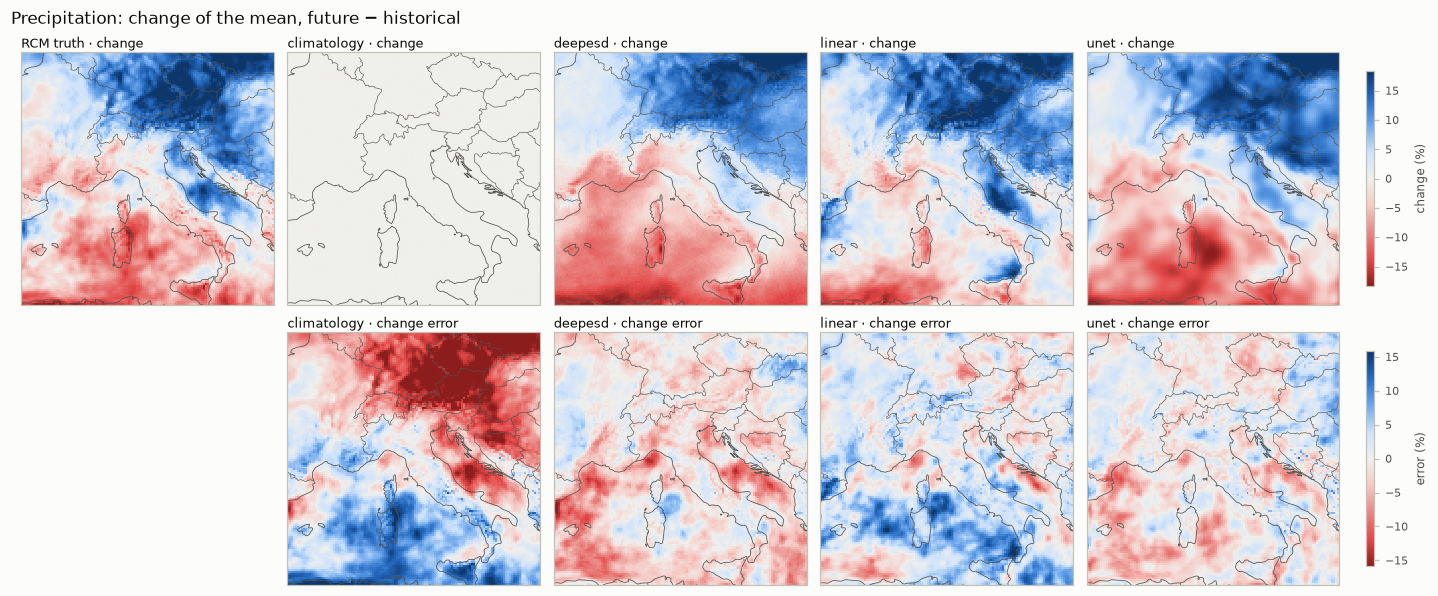

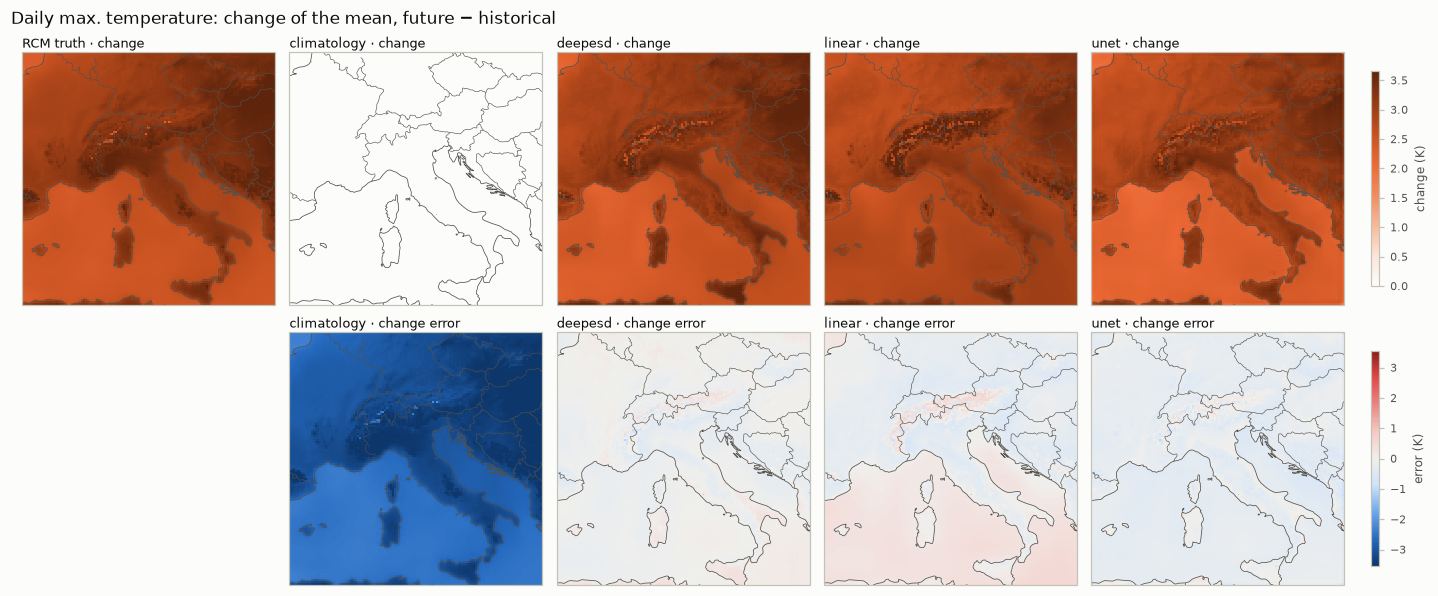

,"pr change (%, domain mean)","tasmax change (K, domain mean)"
model,,
RCM truth,+2.13,+2.97
climatology,-0.00,+0.00
deepesd,+1.11,+2.91
linear,+4.41,+2.95
unet,+1.93,+2.72


In [16]:
DF = {r: results.load_diagnostics(EXP, r, FUTURE) for r in RUNS}
cap(f"change of the time mean from `{SPLIT}` to `{FUTURE}` (pr in %, tasmax in K): truth and each run (top row), "
    "error of each run's change, run − truth (bottom row); table: domain means.", [SPLIT, FUTURE])
for var in EXP.variables:
    P.fig_change_maps(D, DF, var, MG, save=save(f"change_{var}"))
    plt.show()
rows = []
for var in EXP.variables:
    th, tf = float(D[RUNS[0]][f"{var}_mean_true"].mean()), float(DF[RUNS[0]][f"{var}_mean_true"].mean())
    for name, h, f in [("RCM truth", th, tf)] + [
            (r, th + float(D[r][f"{var}_bias_mean"].mean()), tf + float(DF[r][f"{var}_bias_mean"].mean()))
            for r in RUNS]:
        rows.append({"variable": var, "model": name, "change": 100 * (f - h) / h if var == "pr" else f - h})
change = pd.DataFrame(rows).pivot(index="model", columns="variable", values="change")
change.columns = [f"{v} change ({'%' if v == 'pr' else 'K'}, domain mean)" for v in change.columns]
display(change.style.format("{:+.2f}"))

**Findings** *(snapshot 2026-10-30, runs: climatology, deepesd, linear, unet; update when runs change)*
- Truth: tasmax warms by 3.0 K on average, more over the northern land areas than over the sea. pr shows a
  north–south dipole: +10–15% north of the Alps, about −10% over the Mediterranean; +2.1% domain mean.
- Climatology has no change by construction, so its error is the whole signal.
- **tasmax:** linear and DeepESD reproduce the domain-mean warming (2.95 and 2.91 vs. 2.97 K); the U-Net
  underestimates it by about 0.24 K almost everywhere (2.72 K), consistent with its weaker extrapolation of hot
  extremes. The spatial pattern of the change is best captured by DeepESD and the U-Net (correlation with the truth
  0.95–0.96 vs. 0.72 for linear).
- **pr:** DeepESD and the U-Net reproduce the dipole (domain mean +1.1% and +1.9%); linear gives +4.4% because it
  underestimates the drying in the south.

## 10. Ensemble calibration

Only for stochastic runs (more than one member): rank histograms (flat = calibrated, U-shape = under-dispersive,
dome = over-dispersive), spread/skill ratio and CRPS.

In [17]:
stoch = [r for r in RUNS if scores[(scores.run == r)].n_members.max() > 1]
if not stoch:
    print("No stochastic runs evaluated yet.")
else:
    cap("rank histograms of the truth among the ensemble members (every 4th grid point, all days).")
    P.fig_rank_histograms({r: D[r] for r in stoch}, COLORS, EXP.variables, save=save(f"rank_hist_{SPLIT}"))
    plt.show()
    s = scores[(scores.split == SPLIT) & scores.run.isin(stoch) & scores.metric.isin(["CRPS", "Spread/skill"])]
    display(s.pivot_table(index="run", columns=["variable", "metric"], values="value").style.format(fmt))

No stochastic runs evaluated yet.


*No findings yet: all current runs are deterministic. This section fills in with the flow-matching models of Phase C.*

---
**Adding a model.** Implement a `Downscaler` subclass in `src/dslab/models/` (see `linear.py` or `unet.py`),
register it, add `configs/models/<name>.yaml`, then `bash jobs/submit_model.sh alps_esd <name>` (GPU training,
then evaluation) and `sbatch jobs/notebook.sbatch`. The run appears here automatically; update the findings notes.
Pin its colour with `P.RUN_COLORS["<name>"] = P.SERIES[k]` before `run_colors`.